# Chapter 2 

In [6]:
import numpy as np
import matplotlib.pyplot as plt 
from matplotlib.colors  import ListedColormap
import pandas as pd

In [7]:
def plot_decision_regions(X, y, classifier, test_idx=None,
                          resolution=0.02):
    # setup marker generator and color map
    markers = ('o', 's', '^', 'v', '<')
    colors = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    cmap = ListedColormap(colors[:len(np.unique(y))])
     # plot the decision surface
 
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    lab = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    lab = lab.reshape(xx1.shape)
    plt.contourf(xx1, xx2, lab, alpha=0.3, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())
 # plot class examples
    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y == cl, 0],
                    y=X[y == cl, 1],
                    alpha=0.8,
                    c=colors[idx],
                    marker=markers[idx],
                    label=f'Class {cl}',
                    edgecolor='black')
 # highlight test examples
    if test_idx:
 # plot all examples
        X_test, y_test = X[test_idx, :], y[test_idx]
        plt.scatter(X_test[:, 0], X_test[:, 1],
                    c='none', edgecolor='black', alpha=1.0,
                    linewidth=1, marker='o',
                    s=100, label='Test set')

In [8]:
class Perceptron: 
    
    def __init__(self , eta = 0.01 , n_iter = 50 , random_state = 1):
        self.eta = eta 
        self.n_iter = n_iter 
        self.random_state = random_state 

    def fit(self , X , y ): 

        rgen = np.random.RandomState(self.random_state)

        self.w_ = rgen.normal(loc = 0.0 , scale = 0.01 , size = X.shape[1])

        self.b_ = np.float_(0.)
        self.errors_ = []

        for _  in range(self.n_iter): 
            errors = 0 
            for xi , target in zip(X, y): 
                update = self.eta * (target - self.predict(xi))
                self.w_ += update *xi 
                self.b_ += update 
                errors += int(update != 0.0 )
            self.errors_.append(errors)
        return self 
    
    def net_input(self , X): 

        return np.dot(X , self.w_) + self.b_
    
    def predict(self , X): 

        return np.where(self.net_input(X) >= 0.0 , 1 , 0 )

Loading dataset...
From URL: https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data
       0    1    2    3               4
145  6.7  3.0  5.2  2.3  Iris-virginica
146  6.3  2.5  5.0  1.9  Iris-virginica
147  6.5  3.0  5.2  2.0  Iris-virginica
148  6.2  3.4  5.4  2.3  Iris-virginica
149  5.9  3.0  5.1  1.8  Iris-virginica


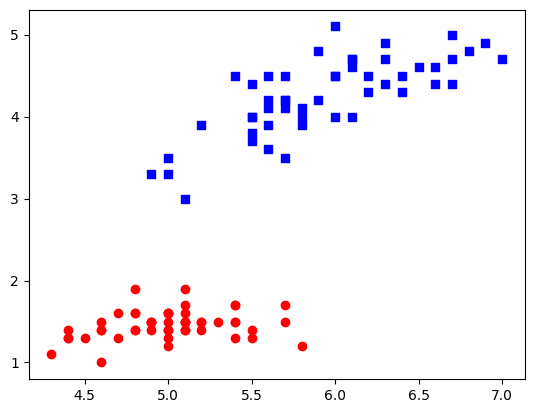

In [4]:
print("==" * 50 ) 
print("Loading dataset...")




s = 'https://archive.ics.uci.edu/ml/'\
      'machine-learning-databases/iris/iris.data'
print('From URL:', s)
df = pd.read_csv(s,
                   header=None,
                  encoding='utf-8')
print(df.tail())

y = df.iloc[0:100, 4].values 
y = np.where(y == "Iris-setosa", 0 , 1 )

X = df.iloc[0:100 , [0,2]].values 

# plot data
plt.scatter(X[:50, 0], X[:50, 1],
            color='red', marker='o', label='Setosa')
plt.scatter(X[50:100, 0], X[50:100, 1],
            color='blue', marker='s', label='Versicolor')



#####################33
#####################33

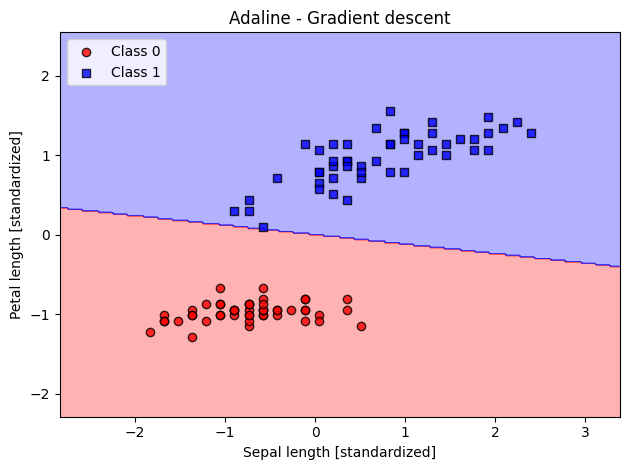

AttributeError: 'Perceptron' object has no attribute 'losses_'

In [10]:


X_std = np.copy(X)
X_std[:,0] = (X[:,0] - X[:,0].mean()) / X[:,0].std()
X_std[:,1] = (X[:,1] - X[:,1].mean()) / X[:,1].std()

ada_gd = Perceptron(n_iter=20, eta=0.5)
ada_gd.fit(X_std, y)
plot_decision_regions(X_std, y, classifier=ada_gd)
plt.title('Adaline - Gradient descent')
plt.xlabel('Sepal length [standardized]')
plt.ylabel('Petal length [standardized]')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()
plt.plot(range(1, len(ada_gd.losses_) + 1), ada_gd.losses_, marker='o')
plt.xlabel('Epochs')
plt.ylabel('Mean squared error')
plt.tight_layout()
plt.show()

In [12]:
class AdalineGD: 
    
    def __init__(self , eta = 0.01 , n_iter = 50 , random_state = 1):
        self.eta = eta 
        self.n_iter = n_iter 
        self.random_state = random_state 
        

    def fit(self , X , y ): 

        rgen = np.random.RandomState(self.random_state)

        self.w_ = rgen.normal(loc = 0.0 , scale = 0.01 , size = X.shape[1])

        self.b_ = np.float_(0.)
        self.losses_ = []

        for _  in range(self.n_iter): 
            net_input = self.net_input(X)
            output = self.activation(net_input)
            errors = (y-output)
            self.w_  += self.eta * 2.0 * X.T.dot(errors) / X.shape[0]
            self.b_  += self.eta * 2.0 * errors.mean()
            loss = (errors**2).mean()
            self.losses_.append(loss)
        return self 
    
    def net_input(self , X): 

        return np.dot(X , self.w_) + self.b_
    
    def activation(self ,X): 

        return X
    
    def predict(self , X): 

        return np.where(self.net_input(X) >= 0.5 , 1 , 0 )

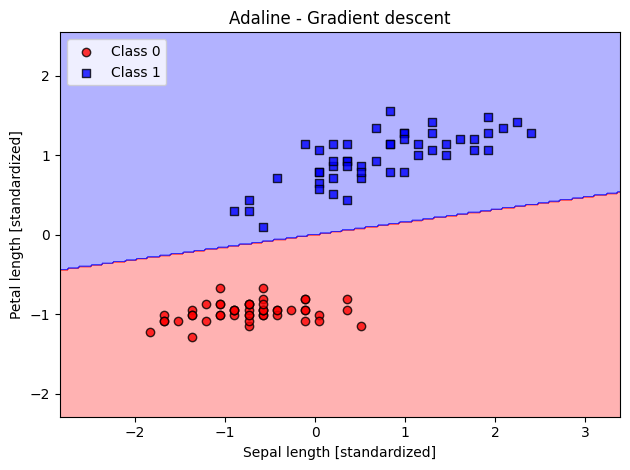

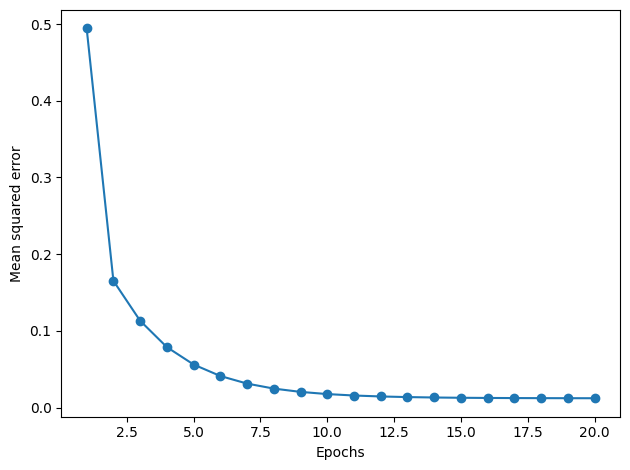

In [13]:
ada_gd = AdalineGD(n_iter=20, eta=0.5)
ada_gd.fit(X_std, y)
plot_decision_regions(X_std, y, classifier=ada_gd)
plt.title('Adaline - Gradient descent')
plt.xlabel('Sepal length [standardized]')
plt.ylabel('Petal length [standardized]')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()
plt.plot(range(1, len(ada_gd.losses_) + 1), ada_gd.losses_, marker='o')
plt.xlabel('Epochs')
plt.ylabel('Mean squared error')
plt.tight_layout()
plt.show()

In [14]:
class AdalineSGD: 
    
    def __init__(self ,shuffle = True , eta = 0.01 , n_iter = 50 , random_state = 1):
        self.eta = eta 
        self.n_iter = n_iter 
        self.random_state = random_state 
        self.w_initialized = False 
        self.shuffle = shuffle 
        

    def fit(self , X , y ): 

        self._initialize_weights(X.shape[1])
        self.losses_ = []

        for _  in range(self.n_iter): 

            if self.shuffle: 
                X,y = self._shuffle(X,y)
            losses = []
            for xi , target in zip(X,y): 
                losses.append(self._update_weights(xi , target))
            avg_loss = np.mean(losses)
            self.losses_.append(avg_loss)

        return self 
    
    def partial_fit(self, X, y):

        if not self.w_initialized:
                    self._initialize_weights(X.shape[1])
        if y.ravel().shape[0] > 1:
            for xi, target in zip(X, y):
                self._update_weights(xi, target)
        else:
                self._update_weights(X, y)
        return self
    
    def _shuffle(self, X, y):
        r = self.rgen.permutation(len(y))
        return X[r], y[r]
    
    def _initialize_weights(self, m):
        self.rgen = np.random.RandomState(self.random_state)
        self.w_ = self.rgen.normal(loc=0.0, scale=0.01,
                                   size=m)
        self.b_ = np.float_(0.)
        self.w_initialized = True
    def _update_weights(self, xi, target):
        output = self.activation(self.net_input(xi))
        error = (target - output)
        self.w_ += self.eta * 2.0 * xi * (error)
        self.b_ += self.eta * 2.0 * error
        loss = error**2
        return loss
   
    
    def net_input(self , X): 

        return np.dot(X , self.w_) + self.b_
    
    def activation(self ,X): 

        return X
    
    def predict(self , X): 

        return np.where(self.net_input(X) >= 0.5 , 1 , 0 )

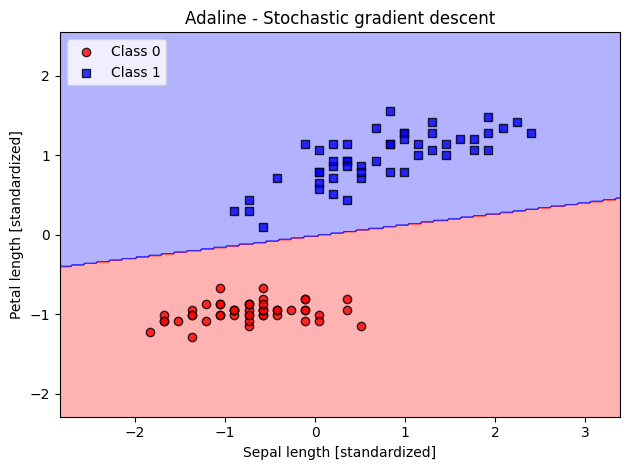

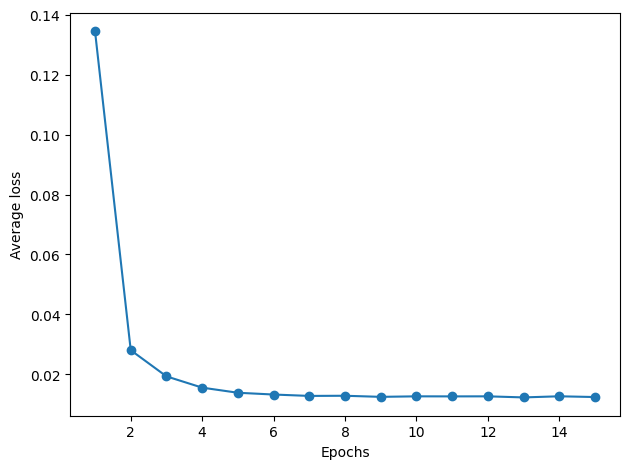

: 

In [ ]:
ada_sgd = AdalineSGD(n_iter=15, eta=0.01, random_state=1)
ada_sgd.fit(X_std, y)
plot_decision_regions(X_std, y, classifier=ada_sgd)
plt.title('Adaline - Stochastic gradient descent')
plt.xlabel('Sepal length [standardized]')
plt.ylabel('Petal length [standardized]')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()
plt.plot(range(1, len(ada_sgd.losses_) + 1), ada_sgd.losses_,
          marker='o')
plt.xlabel('Epochs')
plt.ylabel('Average loss')
plt.tight_layout()
plt.show()